In [1]:
import numpy as np
from matplotlib import pyplot as plt

import sklearn.linear_model
import sklearn.preprocessing
import sklearn.model_selection

In [2]:
x = np.linspace(-np.pi, np.pi, 25)
y = np.cos(x) + np.random.normal(0, 0.15, size=x.shape)

x, y
x = x.reshape(-1, 1)

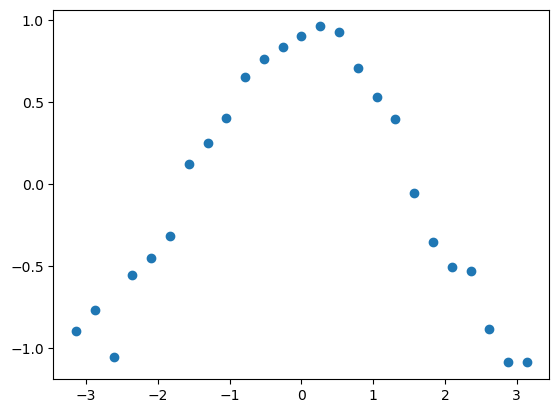

In [3]:
plt.scatter(x, y)

# Underfitting

R^2=0.0008104948186952177


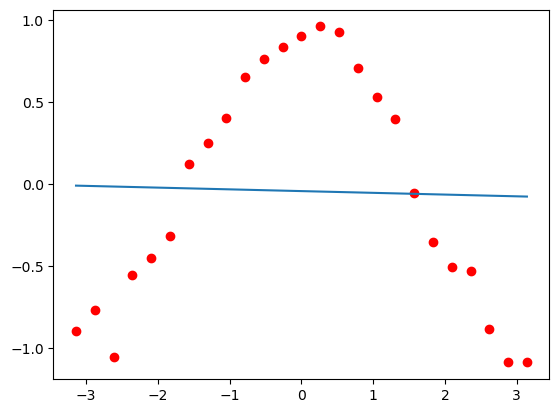

In [4]:
degree = 1
x_hat = sklearn.preprocessing.PolynomialFeatures(degree=degree).fit_transform(x)

regressor = sklearn.linear_model.LinearRegression()
regressor.fit(x_hat, y)

y_hat = regressor.predict(x_hat)
print(f'R^2={regressor.score(x_hat, y)}')
plt.plot(x, y_hat)
plt.scatter(x, y, c='r')

# Overfitting

R^2=0.9999999352719471


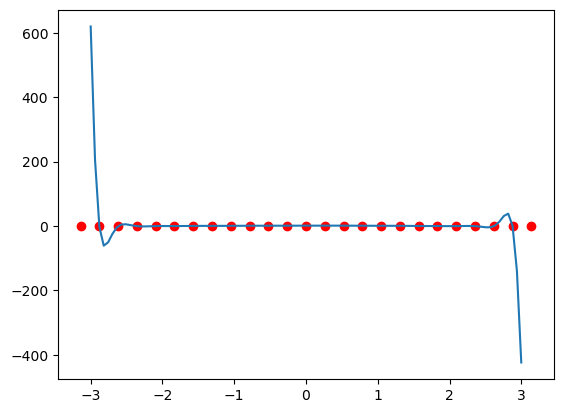

In [12]:
degree = 25
x_hat = sklearn.preprocessing.PolynomialFeatures(degree=degree).fit_transform(x)

regressor = sklearn.linear_model.LinearRegression()
regressor.fit(x_hat, y)

y_hat = regressor.predict(x_hat)
print(f'R^2={regressor.score(x_hat, y)}')

x_values = np.linspace(-3, 3, 100)
x_poly = sklearn.preprocessing.PolynomialFeatures(degree=degree).fit_transform(x_values.reshape(-1, 1))
y_values = regressor.predict(x_poly)
plt.plot(x_values, y_values)
plt.scatter(x, y, c='r')

# Just right?

R^2=0.9834459636124934


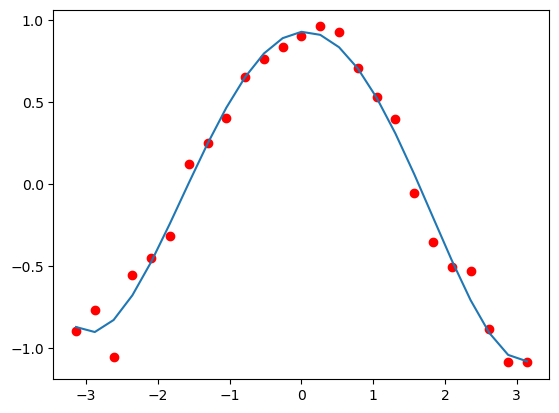

In [13]:
degree = 5
x_hat = sklearn.preprocessing.PolynomialFeatures(degree=degree).fit_transform(x)

regressor = sklearn.linear_model.LinearRegression()
regressor.fit(x_hat, y)

y_hat = regressor.predict(x_hat)
print(f'R^2={regressor.score(x_hat, y)}')
plt.plot(x, y_hat)
plt.scatter(x, y, c='r')

# Train/test split

In [20]:
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(x, y)
print(f'{x_train.shape=}, {x_test.shape=}, {y_train.shape=}, {y_test.shape=}')

x_train.shape=(18, 1), x_test.shape=(7, 1), y_train.shape=(18,), y_test.shape=(7,)


In [15]:
for degree in (1, 5, 25):
    # This is training. Note that we're using fit methods.
    poly_features = sklearn.preprocessing.PolynomialFeatures(degree=degree)
    x_hat = poly_features.fit_transform(x_train)

    regressor = sklearn.linear_model.LinearRegression()
    regressor.fit(x_hat, y_train)
    
    # From here we're testing. Note that we're not using fit any more
    y_hat = regressor.predict(x_hat)
    x_test_hat = poly_features.transform(x_test)  # Note: not fit_transform!
    print(f'{degree=:2d},'
          f'training R^2={regressor.score(x_hat, y_train)},'
          f'testing R^2={regressor.score(x_test_hat, y_test)}')
#     plt.plot(x, y_hat)
#     plt.scatter(x, y, c='r')

degree= 1,training R^2=0.021022224477604157,testing R^2=-0.17982689217523018
degree= 5,training R^2=0.989664861139464,testing R^2=0.9416202125498688
degree=25,training R^2=0.9999999999972349,testing R^2=-7959964390833.027


Degree too low (1) -> underfitting -> low training score, low testing score
Degree too high (25) -> overfitting -> high training score, low testing score
Degree just right (5?) -> high training score, high testing score

# Regularization?

degree=25,training R^2=0.8942960792939607,testing R^2=0.9082824153509883


/usr/lib/python3/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.127e-01, tolerance: 9.354e-04
  model = cd_fast.enet_coordinate_descent(


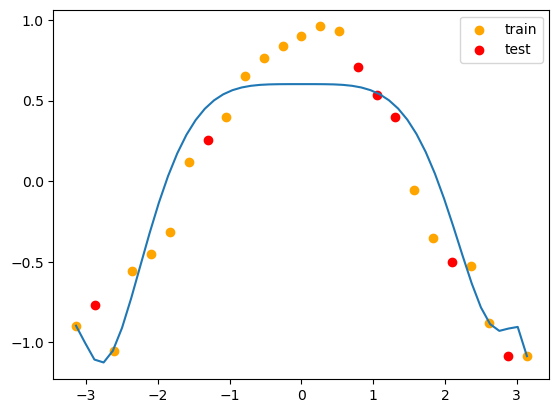

In [22]:
degree = 25

poly_features = sklearn.preprocessing.PolynomialFeatures(degree=degree)
x_hat = poly_features.fit_transform(x_train)

regressor = sklearn.linear_model.ElasticNet(alpha=1)  # Both L1 and L2 regularization
regressor.fit(x_hat, y_train)

# From here we're testing. Note that we're not using fit any more
y_hat = regressor.predict(x_hat)
x_test_hat = poly_features.transform(x_test)  # Note: not fit_transform!
print(f'{degree=:2d},'
      f'training R^2={regressor.score(x_hat, y_train)},'
      f'testing R^2={regressor.score(x_test_hat, y_test)}')


x_vals = np.linspace(np.min(x), np.max(x), 50).reshape(-1, 1)
y_pred = regressor.predict(poly_features.transform(x_vals))
plt.plot(x_vals, y_pred)
plt.scatter(x_train, y_train, c='orange', label='train')
plt.scatter(x_test, y_test, c='red', label='test')
plt.legend()

# Learning curve
Am I overfitting?

In [23]:
degree = 5

train_scores = []
test_scores = []

poly_features = sklearn.preprocessing.PolynomialFeatures(degree=degree)
x_hat = poly_features.fit_transform(x_train)
regressor = sklearn.linear_model.LinearRegression()  # No regularization

for idx in range(1, x_hat.shape[0]):
    regressor.fit(x_hat[:idx], y_train[:idx])

    # From here we're testing. Note that we're not using fit any more
    x_test_hat = poly_features.transform(x_test)  # Note: not fit_transform!
    train_score = regressor.score(x_hat[:idx], y_train[:idx])
    test_score = regressor.score(x_test_hat, y_test)
    train_scores.append(train_score)
    test_scores.append(test_score)

/usr/lib/python3/dist-packages/sklearn/metrics/_regression.py:918: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


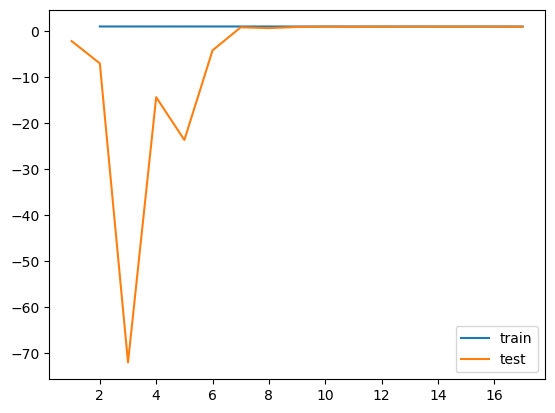

In [24]:
plt.plot(range(1, x_hat.shape[0]), train_scores, label='train')
plt.plot(range(1, x_hat.shape[0]), test_scores, label='test')
plt.legend()

See also sklearn.model_selection.learning_curve
We need to do the .mean because this function does something a little bit more complicated (cross-validation). We'll cover that later in the course. Know that this function will also fit your model.

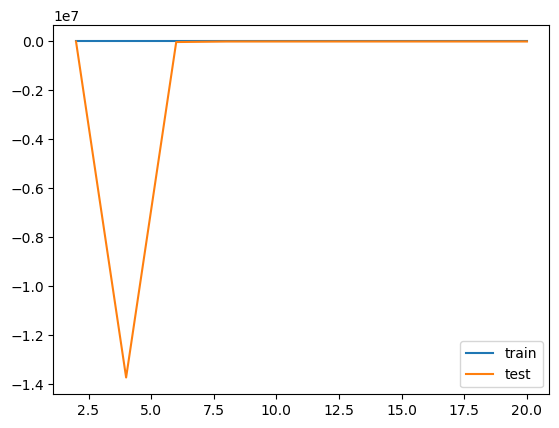

In [25]:
poly_x = sklearn.preprocessing.PolynomialFeatures(degree=3).fit_transform(x)
train_sizes, train_scores, test_scores = sklearn.model_selection.learning_curve(regressor, poly_x, y,
                                                                                train_sizes=np.linspace(2/20, 1, 10))

train_scores = train_scores.mean(axis=1)
test_scores = test_scores.mean(axis=1)
plt.plot(train_sizes, train_scores, label='train')
plt.plot(train_sizes, test_scores, label='test')
plt.legend()

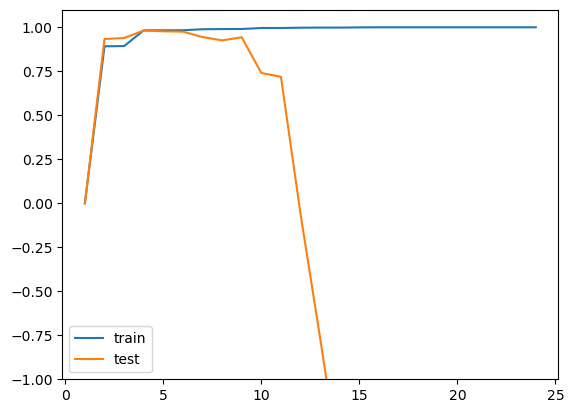

In [29]:
train_scores = []
test_scores = []


for degree in range(1, 25):
    poly_features = sklearn.preprocessing.PolynomialFeatures(degree=degree)
    x_hat = poly_features.fit_transform(x_train)
    regressor = sklearn.linear_model.LinearRegression()  # No regularization

    regressor.fit(x_hat, y_train)

    # From here we're testing. Note that we're not using fit any more
    x_test_hat = poly_features.transform(x_test)  # Note: not fit_transform!
    train_score = regressor.score(x_hat, y_train)
    test_score = regressor.score(x_test_hat, y_test)
    train_scores.append(train_score)
    test_scores.append(test_score)
    
plt.plot(range(1, len(train_scores)+1), train_scores, label='train')
plt.plot(range(1, len(test_scores)+1), test_scores, label='test')
plt.ylim(-1, 1.1)
plt.legend()